Simulate a AT schedule from a trajectory.
- Take in params
- output Simulated AT

Simulate a complete trial. 

In [1]:
%load_ext autoreload
%autoreload 2
import numpy as np
import pandas as pd
from scipy import stats
from pathlib import Path
import shutil
import cmdstanpy
import arviz as az

import matplotlib.pyplot as plt
from at_modelling.LotkaVolterraModel import LotkaVolterraModel
from utils.synth_data import draw_params, complete_param_dict, progress_on_ct, add_cycle_col, plot_n_rand_patients


/Users/80002536/Documents/moffitt/at-modelling/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Lets call instantiate a lotka volterra model. We can call the paramDic to see what params it has set

In [2]:
np.random.seed(1)

#the model is set with default params
lv_model = LotkaVolterraModel()

print(f'Params:', lv_model.param_dic)
print(f'StateVars', lv_model.state_vars)

lv_model.set_params(rS=1)
lv_model.simulate_at(tumour_size_when_progressed=1.2)
lv_model.ode_df

Params: {'DMax': 1, 'rS': 0.027, 'rR': 0.027, 'K': 1, 'dD': 1.5, 'dS': 0.0, 'dR': 0.0, 'S0': 0.74, 'R0': 0.01, 'sigma': 0}
StateVars ['S', 'R']


,Time,DrugConcentration,S,R,TumourSize
0,0.000,1.0,7.400000e-01,0.010000,0.750000
1,0.001,1.0,7.399075e-01,0.010000,0.749908
2,0.002,1.0,7.398150e-01,0.010000,0.749815
3,0.003,1.0,7.397224e-01,0.010000,0.749723
4,0.004,1.0,7.396298e-01,0.010000,0.749630
...,...,...,...,...,...
996,405.996,1.0,7.460966e-10,0.901840,0.901840
997,405.997,1.0,7.460600e-10,0.901842,0.901842
998,405.998,1.0,7.460234e-10,0.901845,0.901845
999,405.999,1.0,7.459867e-10,0.901847,0.901847


But it wont simulate yet. If you uncomment and run the following block, you should get an error that the model doesn't have an 'initialStateList'

In [3]:
#model_example.simulate_at()

We can set our own initial state list, or simply call the Setparams which will get the values from the param dic (R0, S0). Note that a number of arguments can be passed 

We see that We can the print the results. The default time resolution is very high. We can clean the df to longer intervals and also be sure to remove post progression obs

## part 2
We can use the model simulate an entire trial. We can the use this data to test out inferential pipeline such as a bayesian fitting routine. We can add some makeshift, but the proper way to do it would be flexible model code. 

Soft-prior copy of `genertate_synth_AT_trial_data.ipynb`. The prior on turnover is replaced by a prior on
`u = (1 - turnover / (1 - cost)) / n0`, the size the tumour levels off at on continuous therapy relative to its starting size.
`u > 1.2` means the patient progresses. turnover is computed back as `(1 - cost) * (1 - u * n0)`, and `u` has to be below `1 / n0`.
The data go to `../synth_data_u` and the Stan model is `../stan/model_switchable_u.stan`.

P(u < 1.2): 0.07106048489806771


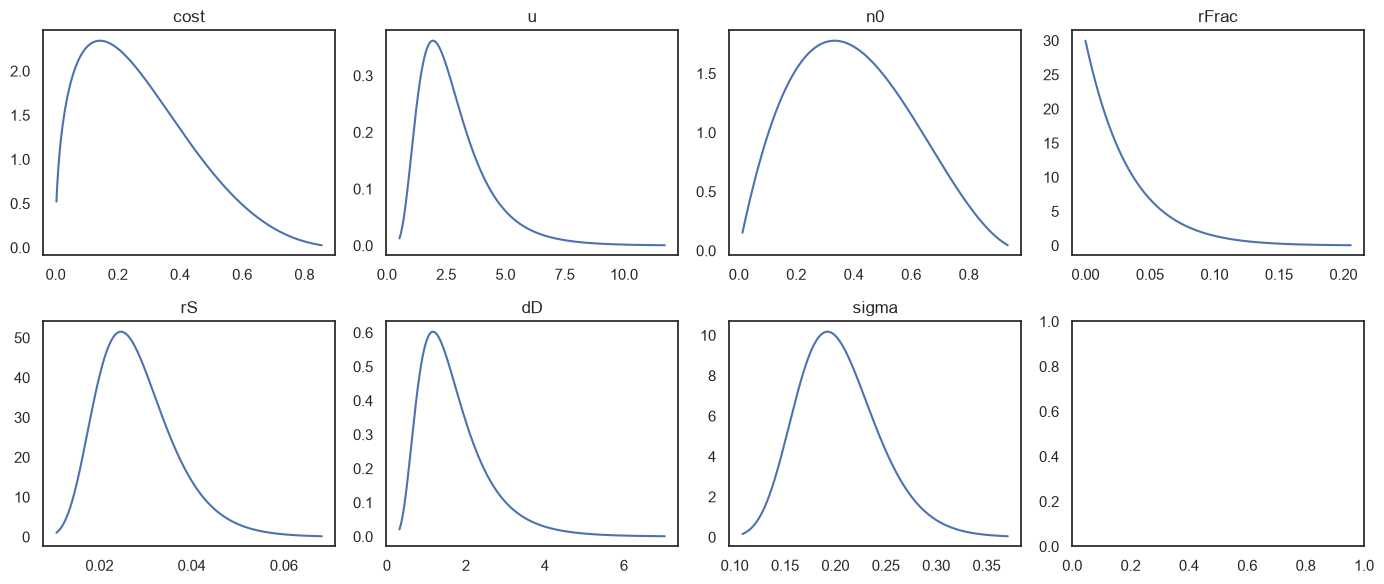

In [4]:
priorDic = {
    "cost":     stats.beta(1.5, 4),                       
    "u":        stats.lognorm(s=0.5, scale=2.5),           
    "n0":       stats.beta(2, 3),
    "rFrac":    stats.beta(1, 30),                    
    "rS":       stats.lognorm(s=0.3, scale=0.027),
    "dD":       stats.lognorm(s=0.5, scale=1.5),
    'sigma':    stats.lognorm(s=.2, scale=.2),
}

fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax, (name, dist) in zip(axes.flat, priorDic.items()):
    x = np.linspace(*dist.ppf([0.001, 0.999]), 400)
    ax.plot(x, dist.pdf(x)); ax.set_title(name)

plt.tight_layout()

#amount of u below 1.2
print('P(u < 1.2):', priorDic["u"].cdf(1.2))

Generate synth patient data

In [5]:
# Generate random patients
n_patients = 10
check_progression = True
t_end = 5000  # Ensure progression occurs in this period

#setup path
out_dir = Path('../synth_data_u')
shutil.rmtree(out_dir, ignore_errors=True) #delete if exists
out_dir.mkdir(parents=True)


#wrap in function and move to stan data file 
#generate synth data
patients, true_params = [], []
for i in range(n_patients):
    #run loop until viable param combination is found
    while True:
        priorDrawDic = draw_params(priorDic)
        if priorDrawDic['u'] * priorDrawDic['n0'] >= 1:
            continue #the plateau can't be above the carrying capacity
        priorDrawDic['turnover'] = (1 - priorDrawDic['cost']) * (1 - priorDrawDic['u'] * priorDrawDic['n0'])
        priorDrawDic['K'] = 1 #hard code carrying cap
        paramDic = complete_param_dict(**{k: v for k, v in priorDrawDic.items() if k != 'u'})
        if not progress_on_ct(paramDic=paramDic):
            print("Analytically doesnt progress CT")
            continue
        model = LotkaVolterraModel(method='RK45', dt=1)
        model.set_params(**{k: v for k, v in paramDic.items() if k not in ("Cost", "Turnover", "n0")})
        model.simulate_at(at_threshold=0.5, interval_length=28, t_end=t_end)
        if not np.isnan(model.ttp) or not check_progression:
            print(f"Check passed or not checking progression on AT! Saving Patient {i} out of {n_patients}")
            break
        print("Check failed")
    #break out while loop and store found param combination. Observation is NaN except at the check-ups
    patients.append(add_cycle_col(model.results_df(), 'DrugConcentration').assign(PatientId=i))
    true_params.append({**priorDrawDic, "PatientId": i})
pd.concat(patients, ignore_index=True).to_csv(out_dir / 'synth_patients.csv', index=False)
pd.DataFrame(true_params).to_csv(out_dir / 'true_params.csv', index=False)

Check passed or not checking progression on AT! Saving Patient 0 out of 10
Check passed or not checking progression on AT! Saving Patient 1 out of 10
Check passed or not checking progression on AT! Saving Patient 2 out of 10
Check passed or not checking progression on AT! Saving Patient 3 out of 10
Check passed or not checking progression on AT! Saving Patient 4 out of 10
Check passed or not checking progression on AT! Saving Patient 5 out of 10
Check passed or not checking progression on AT! Saving Patient 6 out of 10
Check passed or not checking progression on AT! Saving Patient 7 out of 10
Check passed or not checking progression on AT! Saving Patient 8 out of 10
Check passed or not checking progression on AT! Saving Patient 9 out of 10


Lets plot the patients we just generated.

array([[<Axes: title={'center': 'Time'}>,
        <Axes: title={'center': 'Cycle'}>]], dtype=object)

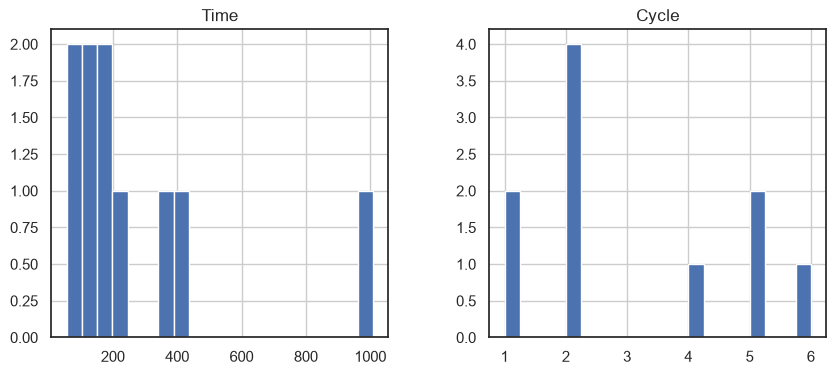

In [6]:
synth_df = pd.read_csv('../synth_data_u/synth_patients.csv')

summary = synth_df.groupby('PatientId').agg({'Time': 'max', 'Cycle': 'max' })
summary.hist(bins=20, figsize=(10, 4))


And we can plot a set of the generated patient trajectories

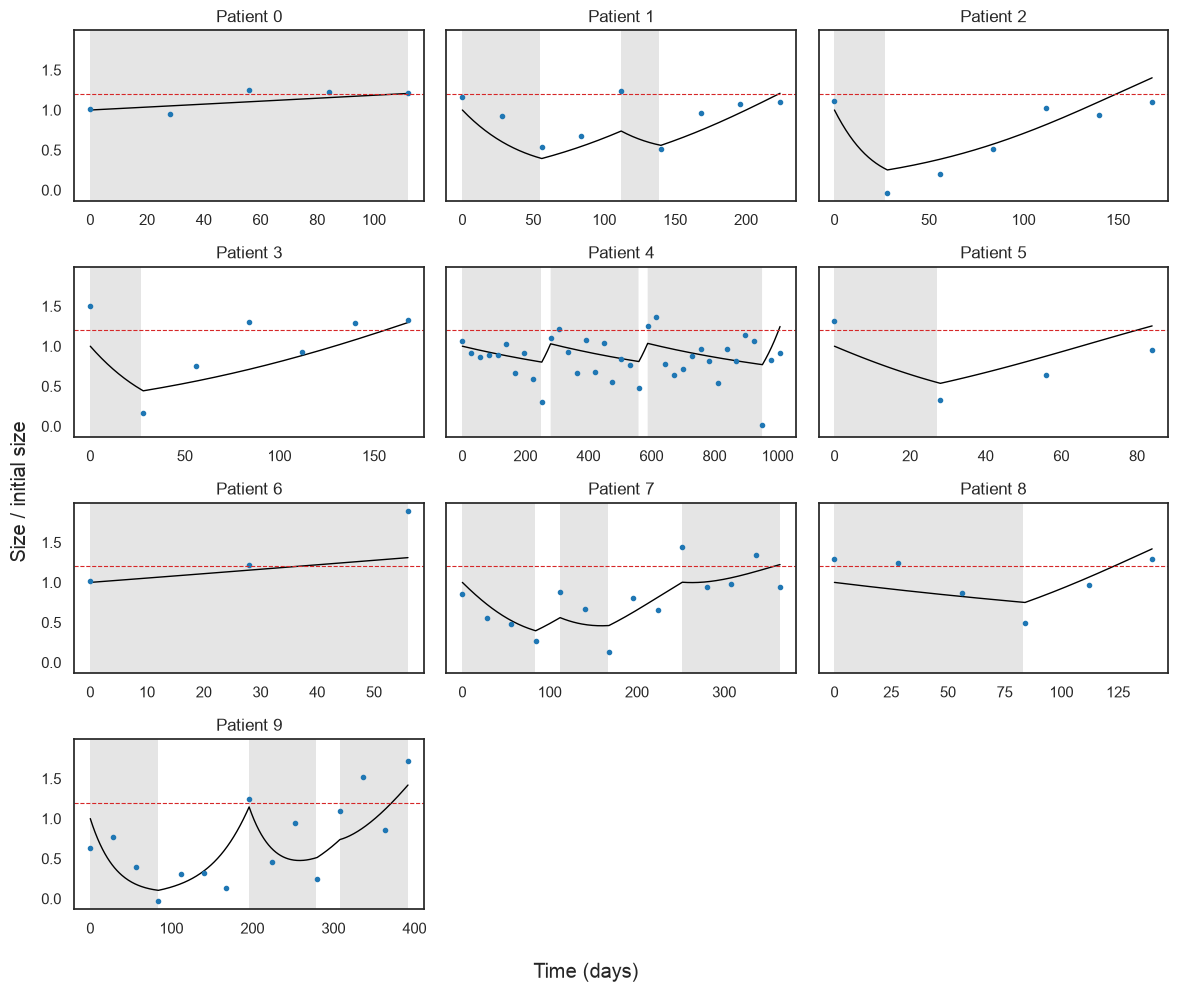

In [7]:
plot_n_rand_patients(synth_df, n=10);


### part 3
Fitig one of these using stan. setup model data

In [8]:
from utils.stan_data import to_stan_prior, make_stan_data, prior_init

patient_id = 3

synth_dir = Path('../synth_data_u')
synth_df = pd.read_csv(synth_dir / 'synth_patients.csv')
stan_model = cmdstanpy.CmdStanModel(stan_file='../stan/model_switchable_u.stan')
priors = {f"{k}_prior": to_stan_prior(d) for k, d in priorDic.items()}
stan_data = {**make_stan_data(synth_df, patient_id=patient_id, priors=priors), 'fit_u': 1, 'u_fixed_val': 0}

First we sample from priors only and compare priors put into the simulator

13:14:08 - cmdstanpy - INFO - CmdStan start processing
13:14:08 - cmdstanpy - INFO - Chain [1] start processing
13:14:08 - cmdstanpy - INFO - Chain [2] start processing
13:14:08 - cmdstanpy - INFO - Chain [3] start processing
13:14:08 - cmdstanpy - INFO - Chain [4] start processing
13:14:10 - cmdstanpy - INFO - Chain [3] done processing
13:14:10 - cmdstanpy - INFO - Chain [1] done processing
13:14:10 - cmdstanpy - INFO - Chain [4] done processing
13:14:12 - cmdstanpy - INFO - Chain [2] done processing
13:14:12 - cmdstanpy - WARNING - Non-fatal error during sampling:
Exception: ode_rk45: ode parameters and data[1] is inf, but must be finite! (in 'model_switchable_u.stan', line 145, column 4 to column 168)
	Exception: ode_rk45: initial state[1] is nan, but must be finite! (in 'model_switchable_u.stan', line 145, column 4 to column 168)
Exception: ode_rk45: ode parameters and data[3] is inf, but must be finite! (in 'model_switchable_u.stan', line 145, column 4 to column 168)
	Exception: o

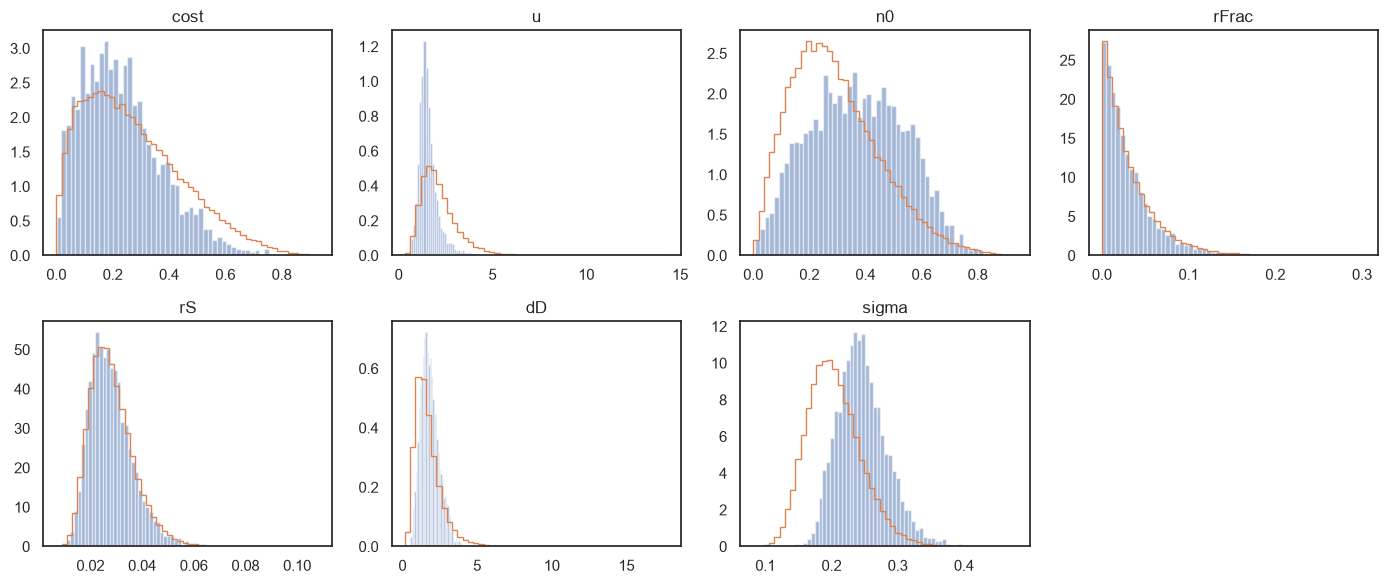

In [9]:
#sample the prior with Stan and compare with priorDic
rng = np.random.default_rng(1)

#move to stan data file
def u_init():
    #redraw until u is below its upper bound 1 / n0
    while True:
        init = prior_init(priorDic, rng)
        if init['u_free'][0] * init['n0_free'][0] < 1:
            return init

#priorDic with the draws where u * n0 >= 1 removed, which is the prior Stan samples
ref = pd.DataFrame({k: d.rvs(100000, random_state=rng) for k, d in priorDic.items()})
ref = ref[ref['u'] * ref['n0'] < 1]

prior_fit = stan_model.sample(data=stan_data, chains=4, seed=1, inits=[u_init() for _ in range(4)], show_progress=False)
prior_draws = prior_fit.draws_pd(list(priorDic))

fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax, (name, dist) in zip(axes.flat, priorDic.items()):
    ax.hist(prior_draws[name], bins=50, density=True, alpha=.5)
    ax.hist(ref[name], bins=50, density=True, histtype='step')
    ax.set_title(f"{name}")
axes.flat[-1].set_visible(False)
fig.tight_layout()

13:14:13 - cmdstanpy - INFO - Chain [1] start processing
13:14:13 - cmdstanpy - INFO - Chain [1] done processing
13:14:13 - cmdstanpy - INFO - CmdStan start processing
chain 1:   0%|          | 0/2000 [00:00<?, ?it/s, (Warmup)]




















chain 1:   5%|▌         | 100/2000 [00:01<00:33, 57.45it/s, (Warmup)]


chain 1:  25%|██▌       | 500/2000 [00:02<00:04, 346.00it/s, (Warmup)]


chain 1:  55%|█████▌    | 1100/2000 [00:02<00:01, 825.99it/s, (Sampling)]

chain 2: 100%|██████████| 2000/2000 [00:03<00:00, 620.51it/s, (Sampling completed)] 

chain 3: 100%|██████████| 2000/2000 [00:03<00:00, 620.52it/s, (Sampling completed)] 


chain 4: 100%|██████████| 2000/2000 [00:03<00:00, 620.52it/s, (Sampling completed)] 


13:14:16 - cmdstanpy - INFO - CmdStan done processing.
13:14:16 - cmdstanpy - WARNING - Non-fatal error during sampling:
Exception: ode_rk45:  Failed to integrate to next output time (28) in less than max_num_steps steps (in 'model_switchable_u.stan', line 145, column 4 to column 168)
Exception: ode_rk45:  Failed to integrate to next output time (28) in less than max_num_steps steps (in 'model_switchable_u.stan', line 145, column 4 to column 168)
Consider re-running with show_console=True if the above output is unclear!
13:14:16 - cmdstanpy - WARNING - Some chains may have failed to converge.
	Chain 2 had 11 divergent transitions (1.1%)
	Use the "diagnose()" method on the CmdStanMCMC object to see further information.



divergences: 11
P(u > 1.2): 0.818


,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
cost,0.23,0.139,0.044,0.48,2380,1678,1.00,0.0026,0.0022
u,1.62,0.59,1,2.7,3252,2645,1.00,0.011,0.018
n0,0.365,0.174,0.092,0.65,1191,1251,1.00,0.0049,0.0024
rFrac,0.033,0.032,0.002,0.093,1960,1482,1.00,0.00059,0.00088
rS,0.0278,0.0082,0.017,0.042,2541,2276,1.00,0.00017,0.00026
dD,1.81,0.62,0.94,2.9,1368,1590,1.00,0.017,0.0099
sigma,0.247,0.037,0.19,0.31,2576,2457,1.00,0.00074,0.00072


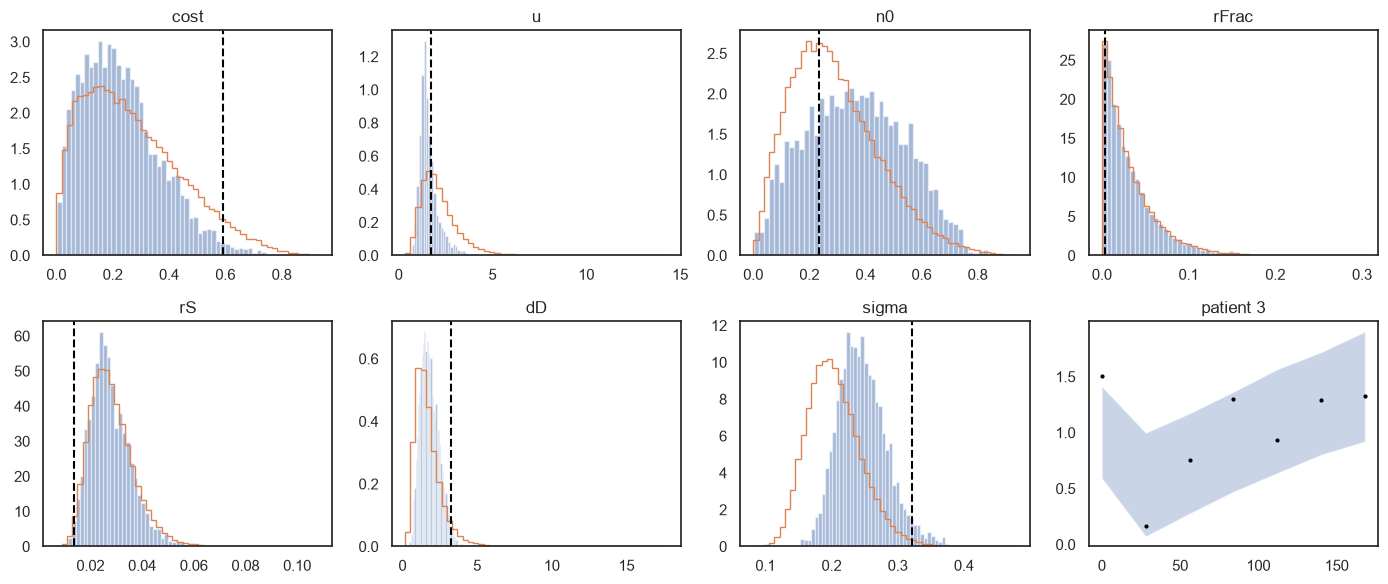

In [10]:
truth = pd.read_csv(synth_dir / 'true_params.csv', index_col='PatientId').loc[patient_id]

#pathfinder inits: one approximate posterior draw per chain, started from a u_init() draw so u is below 1 / n0
pathfinder_fit = stan_model.pathfinder(data={**stan_data, 'prior_only': 0}, seed=1, inits=u_init())
pathfinder_inits = pathfinder_fit.create_inits(seed=1, chains=4)

post_fit = stan_model.sample(data={**stan_data, 'prior_only': 0}, chains=4, seed=3, inits=pathfinder_inits,
                             adapt_delta=0.8, show_progress=True)
idata = az.from_cmdstanpy(posterior=post_fit)
print('divergences:', int(idata.sample_stats['diverging'].sum()))
print('P(u > 1.2):', float((idata.posterior['u'] > 1.2).mean()))
display(az.summary(idata, var_names=list(priorDic)))

post_draws = post_fit.draws_pd(list(priorDic))

fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax, (name, dist) in zip(axes.flat, priorDic.items()):
    ax.hist(post_draws[name], bins=50, density=True, alpha=.5)
    ax.hist(ref[name], bins=50, density=True, histtype='step')
    ax.axvline(truth[name], color='black', ls='--')
    ax.set_title(name)
ax = axes.flat[-1]
ax.fill_between(stan_data['output_times'], *np.percentile(post_fit.stan_variable('PSA_pred'), [5, 95], axis=0), alpha=.3)
ax.plot(stan_data['output_times'], stan_data['PSA_norm'], 'o', ms=2, color='black')
ax.set_title(f'patient {patient_id}')
fig.tight_layout()

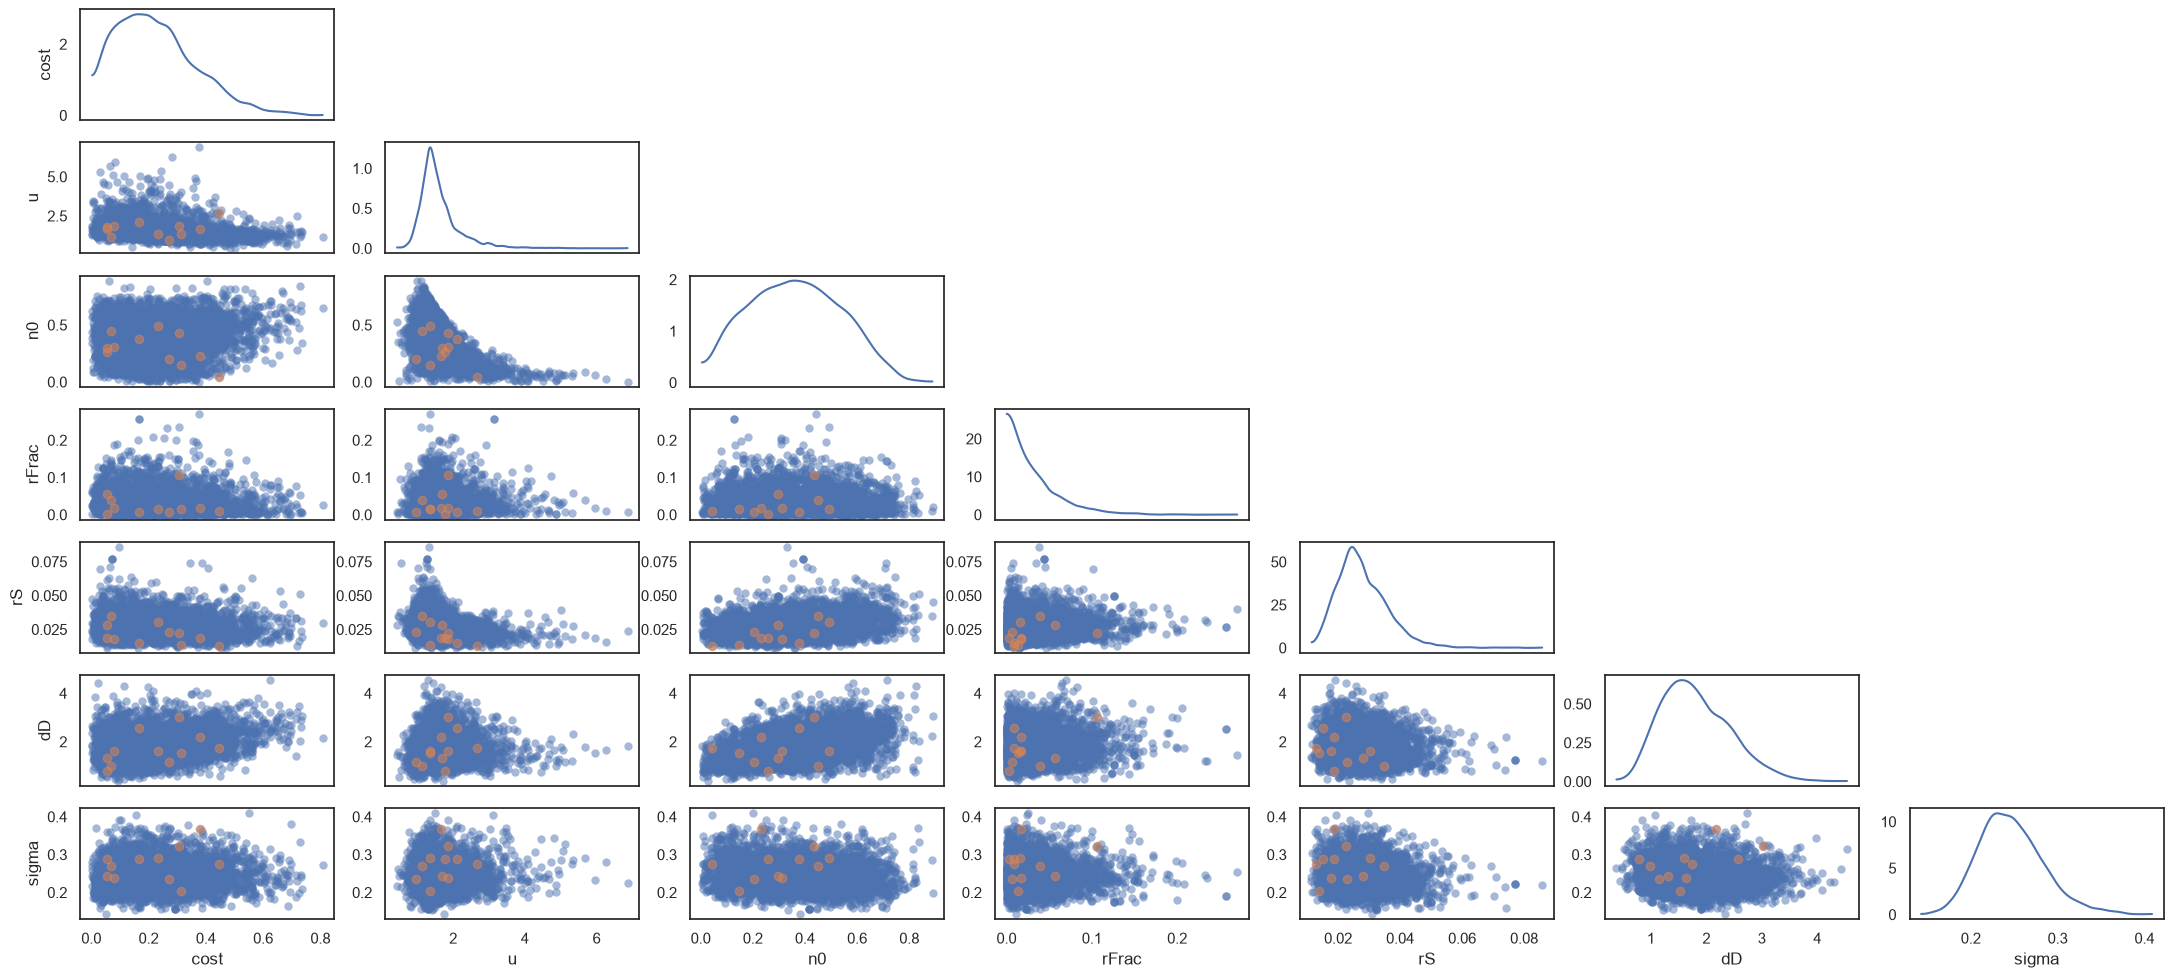

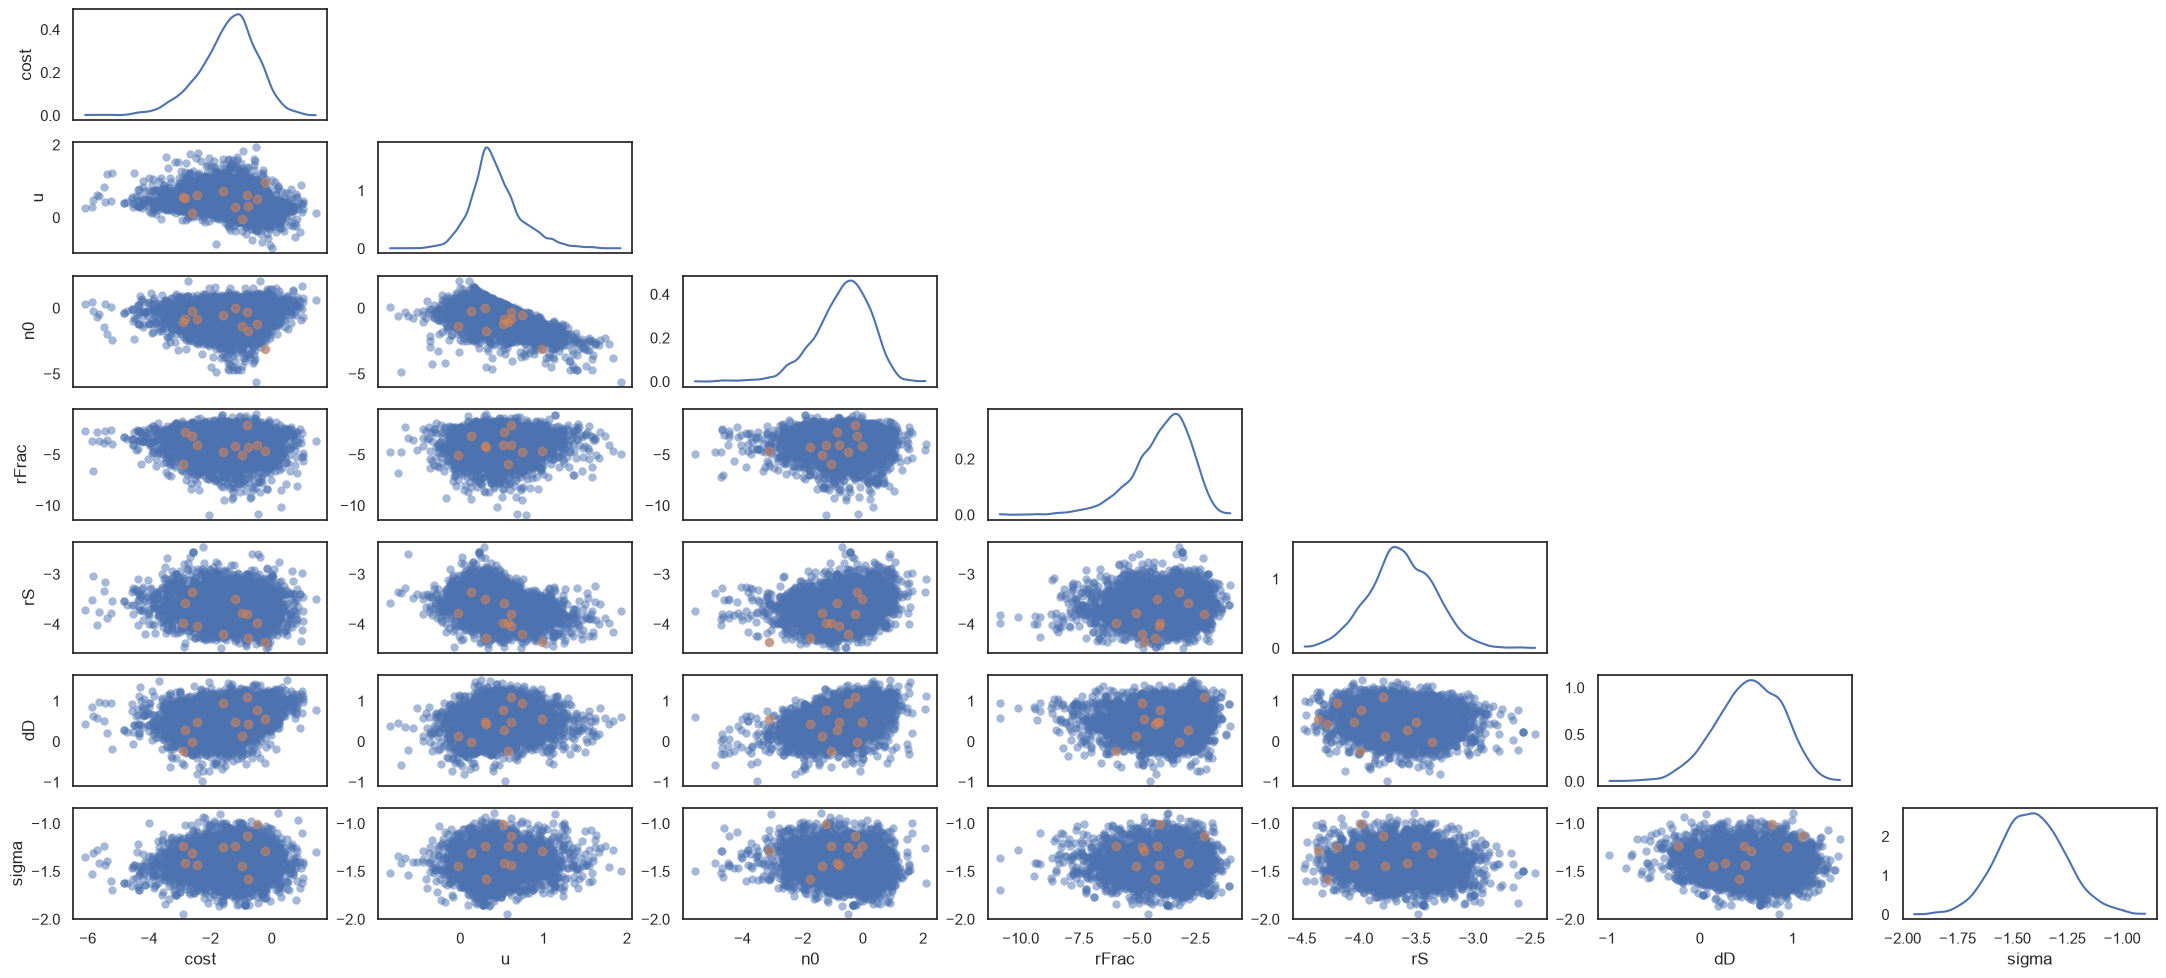

In [11]:
#pair plot on the scales Stan samples on (logit for the betas, log for the lognormals), with the divergent draws marked
from scipy.special import logit
unconstrained = idata.copy()
for name, dist in priorDic.items():
    transform = logit if dist.dist.name == 'beta' else np.log
    unconstrained['posterior'][name] = transform(idata.posterior[name])
az.rcParams['plot.max_subplots'] = 49  #7 parameters need 7 x 7 panels, the default limit is 40
az.plot_pair(idata, var_names=list(priorDic), visuals={'divergence': True});
az.plot_pair(unconstrained, var_names=list(priorDic), visuals={'divergence': True});

In [16]:
# lets def a function to fit a single patient
def fit_patient(patient_id):
    synth_df = pd.read_csv(synth_dir / 'synth_patients.csv')
    patient_df = synth_df[synth_df['PatientId'] == patient_id]
    stan_data = {**make_stan_data(patient_df, patient_id=patient_id, priors=priors), 'fit_u': 1, 'u_fixed_val': 0}
    post_fit = stan_model.sample(data=stan_data, chains=4, seed=4, inits=[u_init() for _ in range(4)],
                                 adapt_delta=0.99, show_progress=False)
    idata = az.from_cmdstanpy(posterior=post_fit)
    return idata


# 
#setup output dir
out_dir = Path('../synth_data_u/fits')
out_dir.mkdir(parents=True, exist_ok=True)
overwrite = True

errors = []


#fit patients
for patient_id in synth_df['PatientId'].unique():
    if (out_dir / f'patient_{patient_id}.nc').exists() and not overwrite:
        continue
    try:
        idata = fit_patient(patient_id)
        idata.to_netcdf(out_dir / f'patient_{patient_id}.nc') 
        print(f'Fitted patient {patient_id} out of {len(synth_df["PatientId"].unique())}')
    except Exception as e:
        #catch error and continue loop.
        errors.append(f'Patient {patient_id}: {e}') 
        continue



#save errors to file
with open(out_dir / 'errors.txt', 'w') as f:
    for error in errors:
        f.write(error + '\n')


13:28:58 - cmdstanpy - INFO - CmdStan start processing
13:28:58 - cmdstanpy - INFO - Chain [1] start processing
13:28:58 - cmdstanpy - INFO - Chain [2] start processing
13:28:58 - cmdstanpy - INFO - Chain [3] start processing
13:28:58 - cmdstanpy - INFO - Chain [4] start processing
13:29:00 - cmdstanpy - INFO - Chain [4] done processing
13:29:00 - cmdstanpy - INFO - Chain [3] done processing
13:29:00 - cmdstanpy - INFO - Chain [2] done processing
13:29:00 - cmdstanpy - INFO - Chain [1] done processing
13:29:00 - cmdstanpy - WARNING - Non-fatal error during sampling:
Exception: ode_rk45: ode parameters and data[2] is nan, but must be finite! (in 'model_switchable_u.stan', line 145, column 4 to column 168)
Consider re-running with show_console=True if the above output is unclear!
13:29:00 - cmdstanpy - INFO - CmdStan start processing
13:29:00 - cmdstanpy - INFO - Chain [1] start processing
13:29:00 - cmdstanpy - INFO - Chain [2] start processing
13:29:00 - cmdstanpy - INFO - Chain [3] st

Fitted patient 0 out of 10


13:29:07 - cmdstanpy - INFO - Chain [2] done processing
13:29:08 - cmdstanpy - INFO - Chain [3] done processing
13:29:09 - cmdstanpy - INFO - Chain [1] done processing
13:29:09 - cmdstanpy - INFO - Chain [4] done processing
13:29:09 - cmdstanpy - WARNING - Non-fatal error during sampling:
Exception: ode_rk45: initial state[1] is nan, but must be finite! (in 'model_switchable_u.stan', line 145, column 4 to column 168)
Exception: ode_rk45: initial state[1] is nan, but must be finite! (in 'model_switchable_u.stan', line 145, column 4 to column 168)
Consider re-running with show_console=True if the above output is unclear!
13:29:09 - cmdstanpy - INFO - CmdStan start processing
13:29:09 - cmdstanpy - INFO - Chain [1] start processing
13:29:09 - cmdstanpy - INFO - Chain [2] start processing
13:29:09 - cmdstanpy - INFO - Chain [3] start processing
13:29:09 - cmdstanpy - INFO - Chain [4] start processing
13:29:14 - cmdstanpy - INFO - Chain [1] done processing
13:29:15 - cmdstanpy - INFO - Chai

Fitted patient 2 out of 10


13:29:19 - cmdstanpy - INFO - Chain [2] done processing
13:29:20 - cmdstanpy - INFO - Chain [4] done processing
13:29:20 - cmdstanpy - INFO - Chain [3] done processing
13:29:20 - cmdstanpy - INFO - Chain [1] done processing
13:29:20 - cmdstanpy - WARNING - Non-fatal error during sampling:
Exception: ode_rk45: initial state[1] is nan, but must be finite! (in 'model_switchable_u.stan', line 145, column 4 to column 168)
Exception: ode_rk45: ode parameters and data[1] is inf, but must be finite! (in 'model_switchable_u.stan', line 145, column 4 to column 168)
Consider re-running with show_console=True if the above output is unclear!
13:29:20 - cmdstanpy - INFO - CmdStan start processing
13:29:20 - cmdstanpy - INFO - Chain [1] start processing
13:29:20 - cmdstanpy - INFO - Chain [2] start processing
13:29:20 - cmdstanpy - INFO - Chain [3] start processing
13:29:20 - cmdstanpy - INFO - Chain [4] start processing
13:29:55 - cmdstanpy - INFO - Chain [1] done processing
13:29:55 - cmdstanpy - I

KeyboardInterrupt: 

In [15]:
import arviz_stats as azs

#loop over files in fit folder
for path in sorted(Path('../synth_data_u/fits').glob('*.nc')):
    # read in fit
    idata = az.from_netcdf(path)
    # call arviz diagnose on fit
    problematic, diagnostics = azs.diagnose(idata, var_names=list(priorDic), show_diagnostics=False, return_diagnostics=True)
    if problematic: 
        print(f'{path.name}: {diagnostics}\n')

patient_4.nc: {'divergent': {'n_divergent': 1, 'pct': np.float64(0.025), 'total_samples': np.int64(4000)}, 'bfmi': {'bfmi_values': array([0.95378195, 0.87911916, 0.98173192, 0.89083995]), 'failed_chains': [], 'threshold': 0.3}, 'ess': {'bad_params': [], 'ess_values': <xarray.Dataset> Size: 0B
Dimensions:  ()
Data variables:
    *empty*, 'threshold_ratio': 0.001, 'total_samples': np.int64(4000)}, 'rhat': {'bad_params': [], 'rhat_values': <xarray.Dataset> Size: 0B
Dimensions:  ()
Data variables:
    *empty*, 'threshold': 1.01}}

